In [3]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import os
os.makedirs('results', exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cpu


In [4]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = 'CNN_deep'
dataset = 'MNIST'
save_model_path = f'results/{model_type}_{dataset}.pt'

In [5]:
transform = transforms.ToTensor()
train_DS= datasets.MNIST(root = 'data', train = True, download = True, transform = transform)
test_DS = datasets.MNIST(root = 'data', train = False, download = True, transform = transform)
train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle = True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle = True)

['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
{'0 - zero': 0, '1 - one': 1, '2 - two': 2, '3 - three': 3, '4 - four': 4, '5 - five': 5, '6 - six': 6, '7 - seven': 7, '8 - eight': 8, '9 - nine': 9}
torch.Size([32, 1, 28, 28])
4 - four


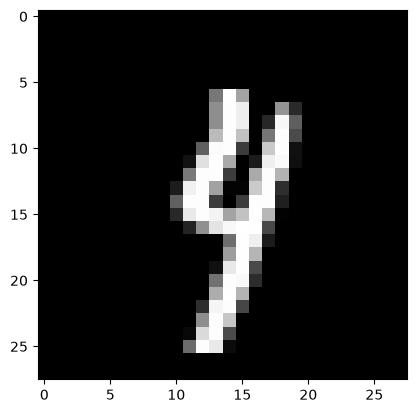

In [6]:
print(test_DS.classes)
print(test_DS.class_to_idx)

x_batch, y_batch = next(iter(train_DL))
print(x_batch.shape)

plt.imshow(x_batch[0,0], cmap = 'gray')
print(test_DS.classes[y_batch[0]])

In [7]:
class CNN(nn.Module):                                               # x_batch.shape -> (32, 1, 28, 28)
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(nn.Conv2d(1, 8, 3, padding = 1),     # (32,8,28,28)
                                    nn.BatchNorm2d(8),
                                    nn.ReLU(),
                                    )
        self.Maxpool1 = nn.MaxPool2d(2)                                 # (32,8,14,14)
        self.conv2 = nn.Sequential(nn.Conv2d(8, 16, 3, padding=1),      # (32,16,14,14)
                                    nn.BatchNorm2d(16),
                                    nn.ReLU()
                                    )
        self.Maxpool2 = nn.MaxPool2d(2)                                 # (32,16,7,7)
        self.conv3 = nn.Sequential(nn.Conv2d(16, 32,3, padding=1),      # (32,32,7,7)
                                    nn.BatchNorm2d(32),
                                    nn.ReLU()
                                    )
        self.Maxpool3 = nn.MaxPool2d(2)                                 # (32,32,3.5,3.5) -> MaxPool1의 기본설정 ceil_mode=False(소수점 버림)  => (32,32,3,3)
        self.fc = nn.Linear(32*3*3, 10)    

    def forward(self, x):
        x = self.conv1(x)
        x = self.Maxpool1(x)
        x = self.conv2(x)
        x = self.Maxpool2(x)
        x = self.conv3(x)
        x = self.Maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

# 은닉층 개수 늘리기
class CNN_deep(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv_block1 = nn.Sequential(nn.Conv2d(1,32,3, padding=1),
                                        nn.BatchNorm2d(32),
                                        nn.ReLU(),
                                        nn.Conv2d(32, 32,3,padding=1),
                                        nn.BatchNorm2d(32),
                                        nn.ReLU()
                                        )
        self.Maxpool1 = nn.MaxPool2d(2) 

        self.conv_block2 = nn.Sequential(nn.Conv2d(32,64,3, padding=1),
                                        nn.BatchNorm2d(64),
                                        nn.ReLU(),
                                        nn.Conv2d(64,64,3,padding=1),
                                        nn.BatchNorm2d(64),
                                        nn.ReLU(),
                                        nn.Conv2d(64,64,3,padding=1) ,
                                        nn.BatchNorm2d(64),
                                        nn.ReLU()
                                        )
        self.Maxpool2 = nn.MaxPool2d(2)

        self.conv_block3 = nn.Sequential(nn.Conv2d(64,128,3, padding=1),
                                        nn.BatchNorm2d(128),
                                        nn.ReLU(),
                                        nn.Conv2d(128,128,3,padding=1),
                                        nn.BatchNorm2d(128),
                                        nn.ReLU(),
                                        nn.Conv2d(128,128,3,padding=1) ,
                                        nn.BatchNorm2d(128),
                                        nn.ReLU()
                                        )
        self.Maxpool3 = nn.MaxPool2d(2)

        self.classifier = nn.Sequential(nn.Linear(128*3*3, 512),
                                        nn.ReLU(),
                                        nn.Linear(512,10))

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.Maxpool1(x)
        x = self.conv_block2(x)
        x = self.Maxpool2(x)   
        x = self.conv_block3(x)
        x = self.Maxpool3(x)   
        x = torch.flatten(x, start_dim=1)                  
        x = self.classifier(x)
        return x

In [8]:
model = globals()[model_type]().to(DEVICE)
print(model)

x_batch, _ = next(iter(train_DL))
print(x_batch.shape)

model.eval()
with torch.no_grad():
    print(model(x_batch.to(DEVICE)).shape)

CNN_deep(
  (conv_block1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
  )
  (Maxpool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
 

Epoch : 1, train loss : 0.105
------------------------------
Epoch : 2, train loss : 0.042
------------------------------
Epoch : 3, train loss : 0.034
------------------------------
Epoch : 4, train loss : 0.028
------------------------------
Epoch : 5, train loss : 0.023
------------------------------


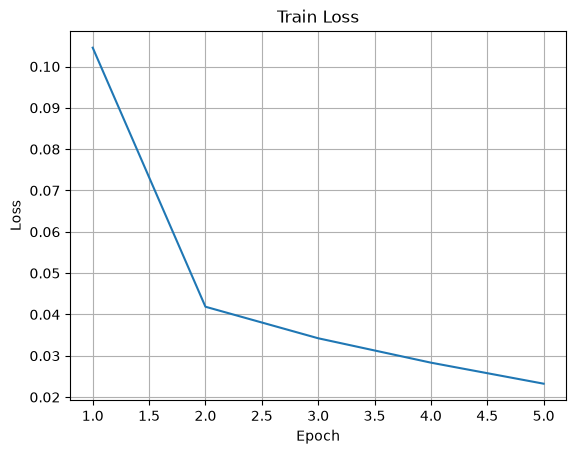

In [9]:
if new_model_train:
    optimizer = optim.Adam(model.parameters(), lr = LR)
    loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

    torch.save(model, save_model_path)

    plt.figure()
    plt.plot(range(1, EPOCH+1), loss_history)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Train Loss')
    plt.grid()

In [10]:
load_model = torch.load(save_model_path, map_location=DEVICE, weights_only=False)


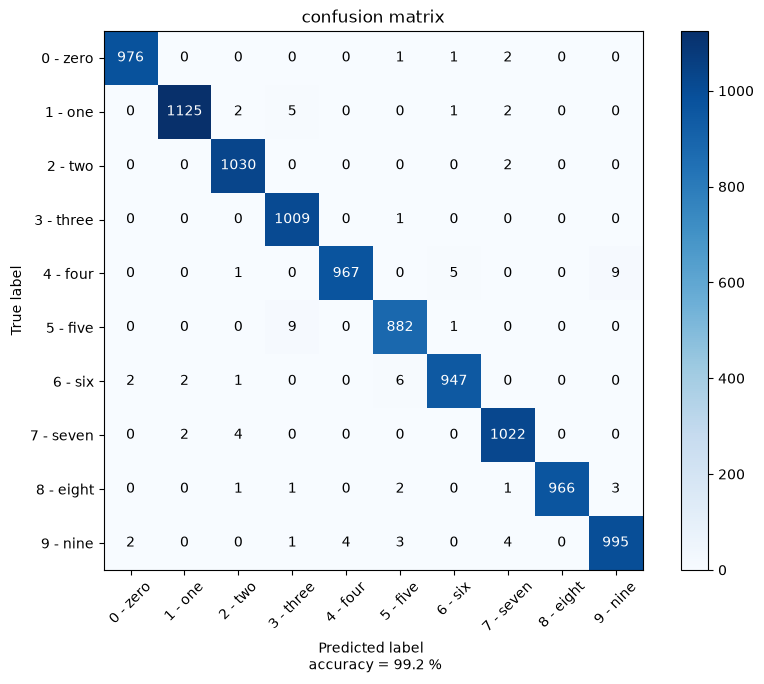

In [11]:
confusion = get_conf(load_model, test_DL)
plot_confusion_matrix(confusion, test_DS.classes)
plt.xticks(rotation=45);

torch.Size([32, 32, 28, 28])
torch.Size([32, 64, 14, 14])
torch.Size([32, 128, 7, 7])


Text(0.5, 1.0, '2 - two (2 - two)')

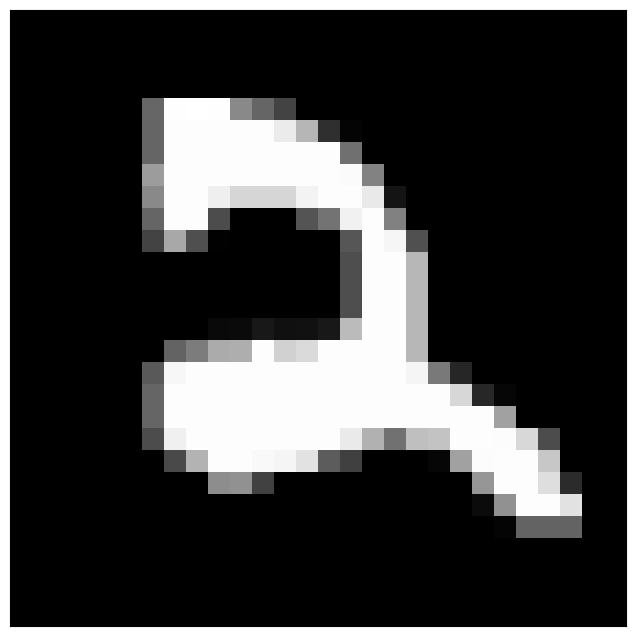

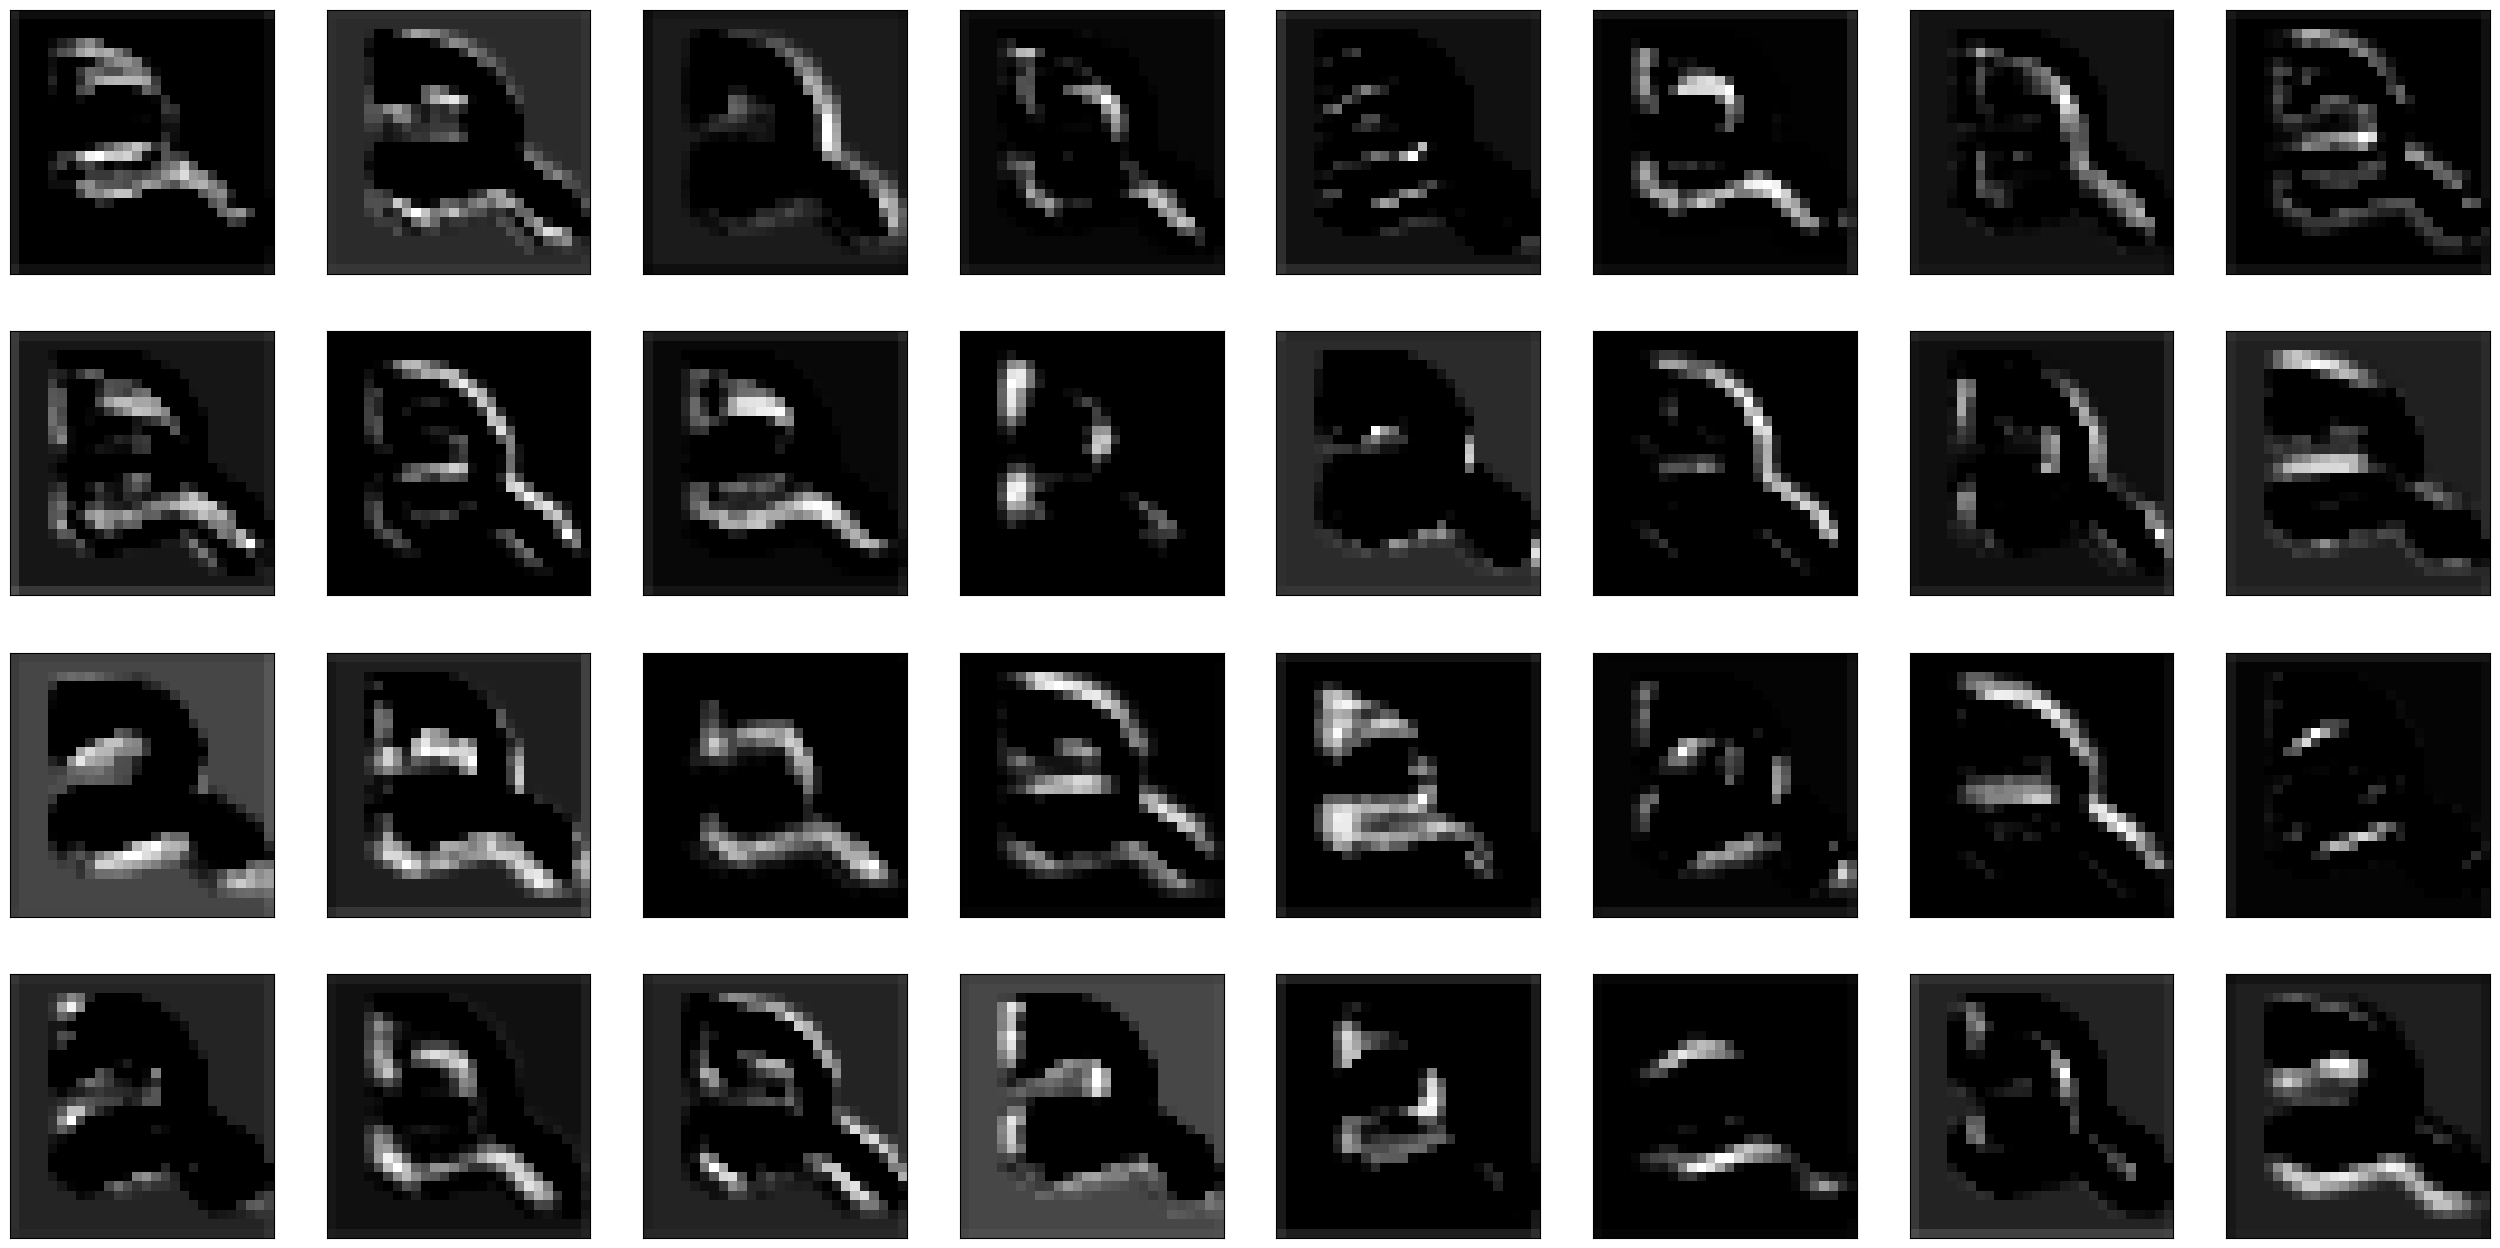

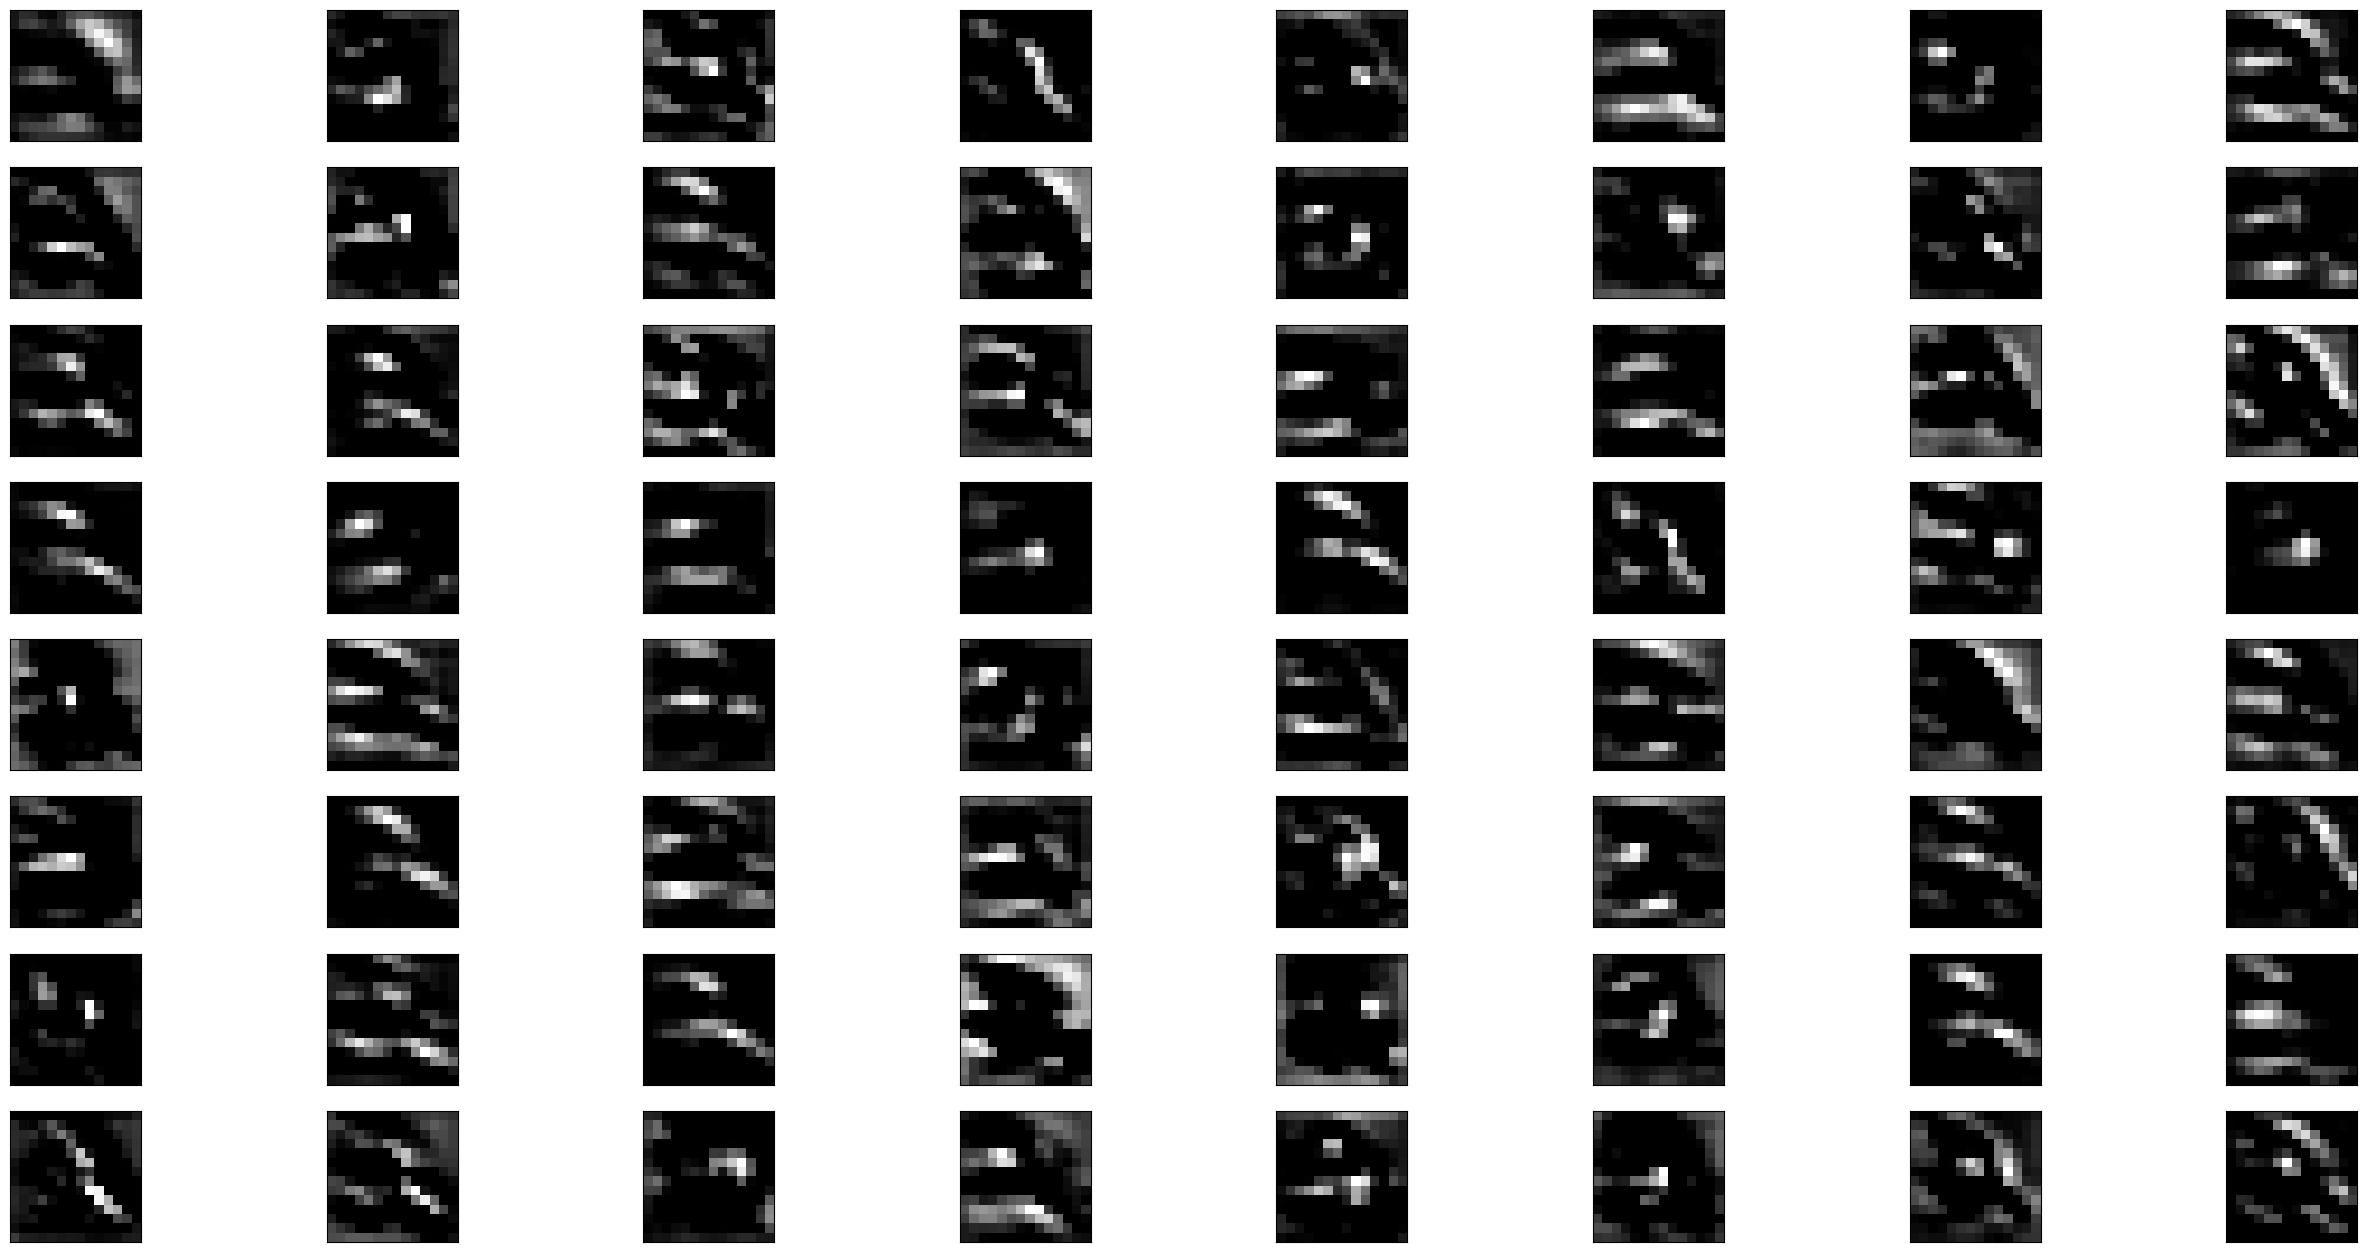

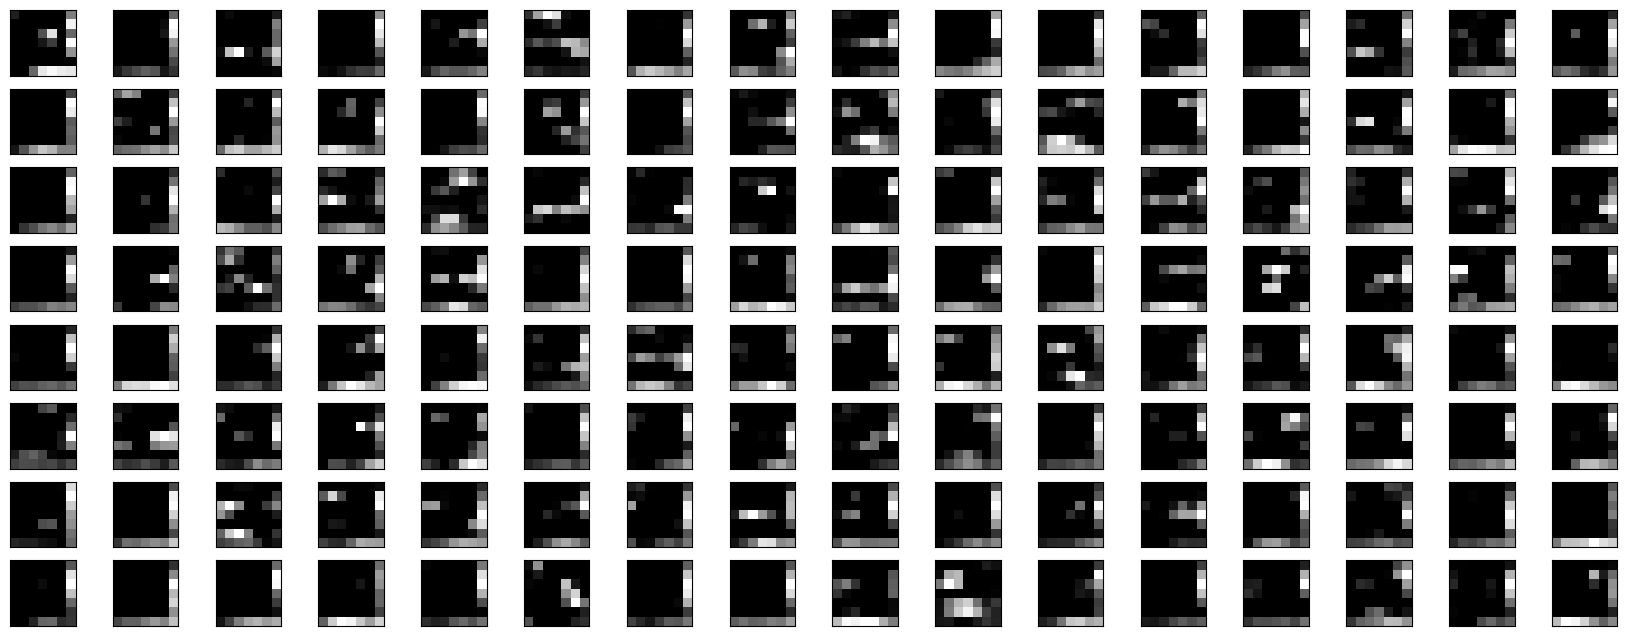

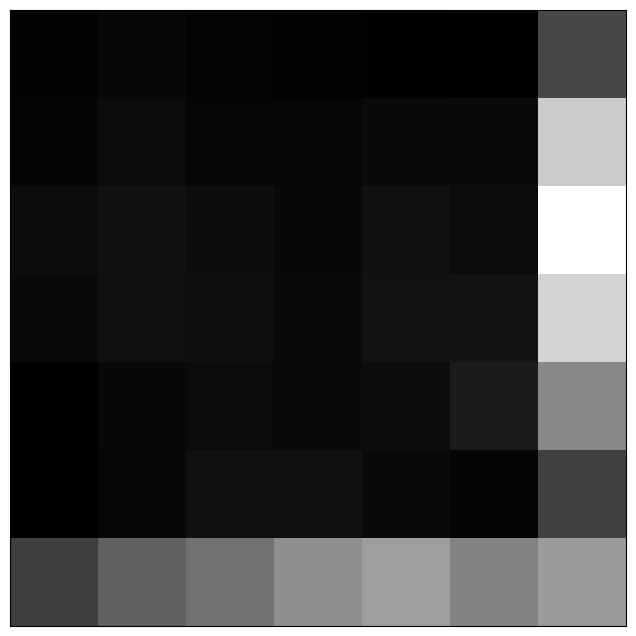

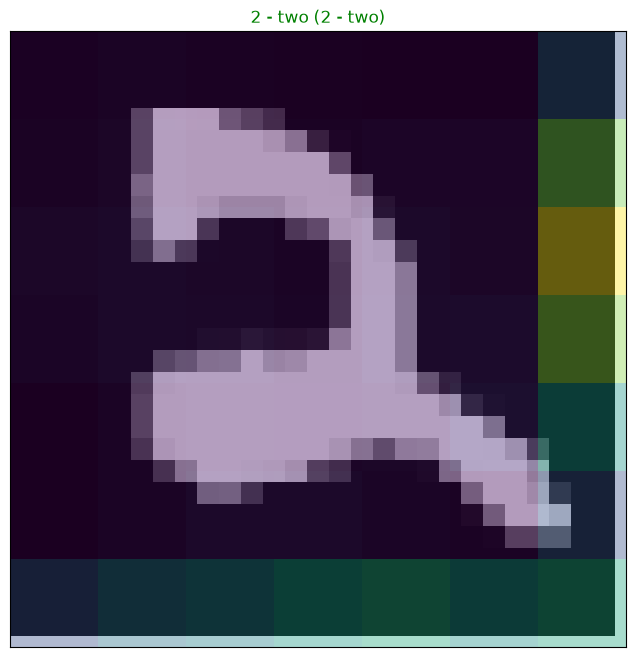

In [12]:
load_model.eval()
with torch.no_grad():
    x_batch, y_batch = next(iter(test_DL))
    x_batch = x_batch.to(DEVICE)
    y_batch = y_batch.to(DEVICE)
    y_hat = load_model(x_batch)
    pred = y_hat.argmax(dim=1)




    if model_type =='CNN':
        feature_map1 = load_model.conv1(x_batch)
        feature_map2 = load_model.conv2(load_model.Maxpool1(feature_map1))
        feature_map3 = load_model.conv3(load_model.Maxpool2(feature_map2))

    elif model_type =='CNN_deep':
        feature_map1 = load_model.conv_block1(x_batch)
        feature_map2 = load_model.conv_block2(load_model.Maxpool1(feature_map1))
        feature_map3 = load_model.conv_block3(load_model.Maxpool2(feature_map2))

x_batch = x_batch.cpu()
feature_map1 = feature_map1.cpu()
feature_map2 = feature_map2.cpu()
feature_map3 = feature_map3.cpu()

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(x_batch[0,0], cmap = 'gray')

print(feature_map1.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map1.shape[1]):
    plt.subplot(4,8, idx +1, xticks =[], yticks=[])
    plt.imshow(feature_map1[0,idx], cmap='gray')

print(feature_map2.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map2.shape[1]):
    plt.subplot(8,8, idx +1, xticks =[], yticks=[])
    plt.imshow(feature_map2[0,idx], cmap='gray')

print(feature_map3.shape)
plt.figure(figsize=(21,8))
for idx in range(feature_map3.shape[1]):
    plt.subplot(8,16, idx +1, xticks =[], yticks=[])
    plt.imshow(feature_map3[0,idx], cmap='gray')

summed_map = feature_map3.sum(dim=1)
plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(summed_map[0], cmap='gray')

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(x_batch[0,0], cmap='gray')
plt.imshow(summed_map[0], extent=[0,28,28,0], alpha=0.4, cmap='viridis')
pred_item = test_DS.classes[pred[0].item()]
true_item = test_DS.classes[y_batch[0].item()]
plt.title(f'{pred_item} ({true_item})', color = 'g' if pred_item == true_item else 'r')

torch.Size([1, 32, 28, 28])
torch.Size([1, 64, 14, 14])
torch.Size([1, 128, 7, 7])


Text(0.5, 1.0, '2 - two (6 - six)')

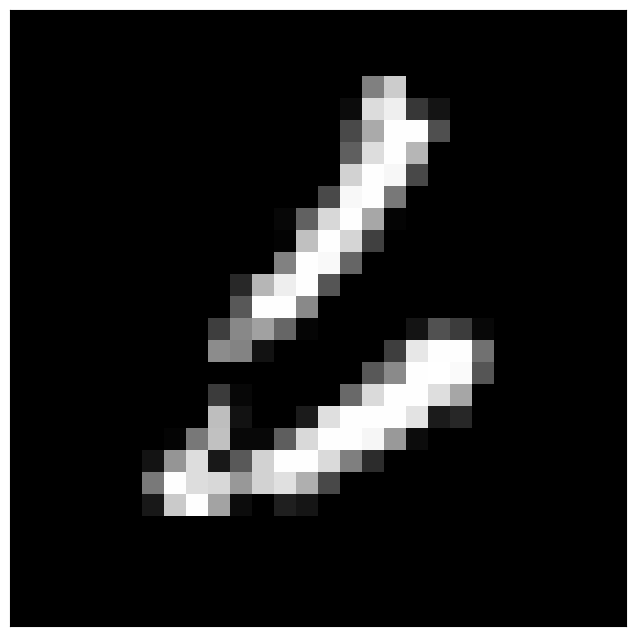

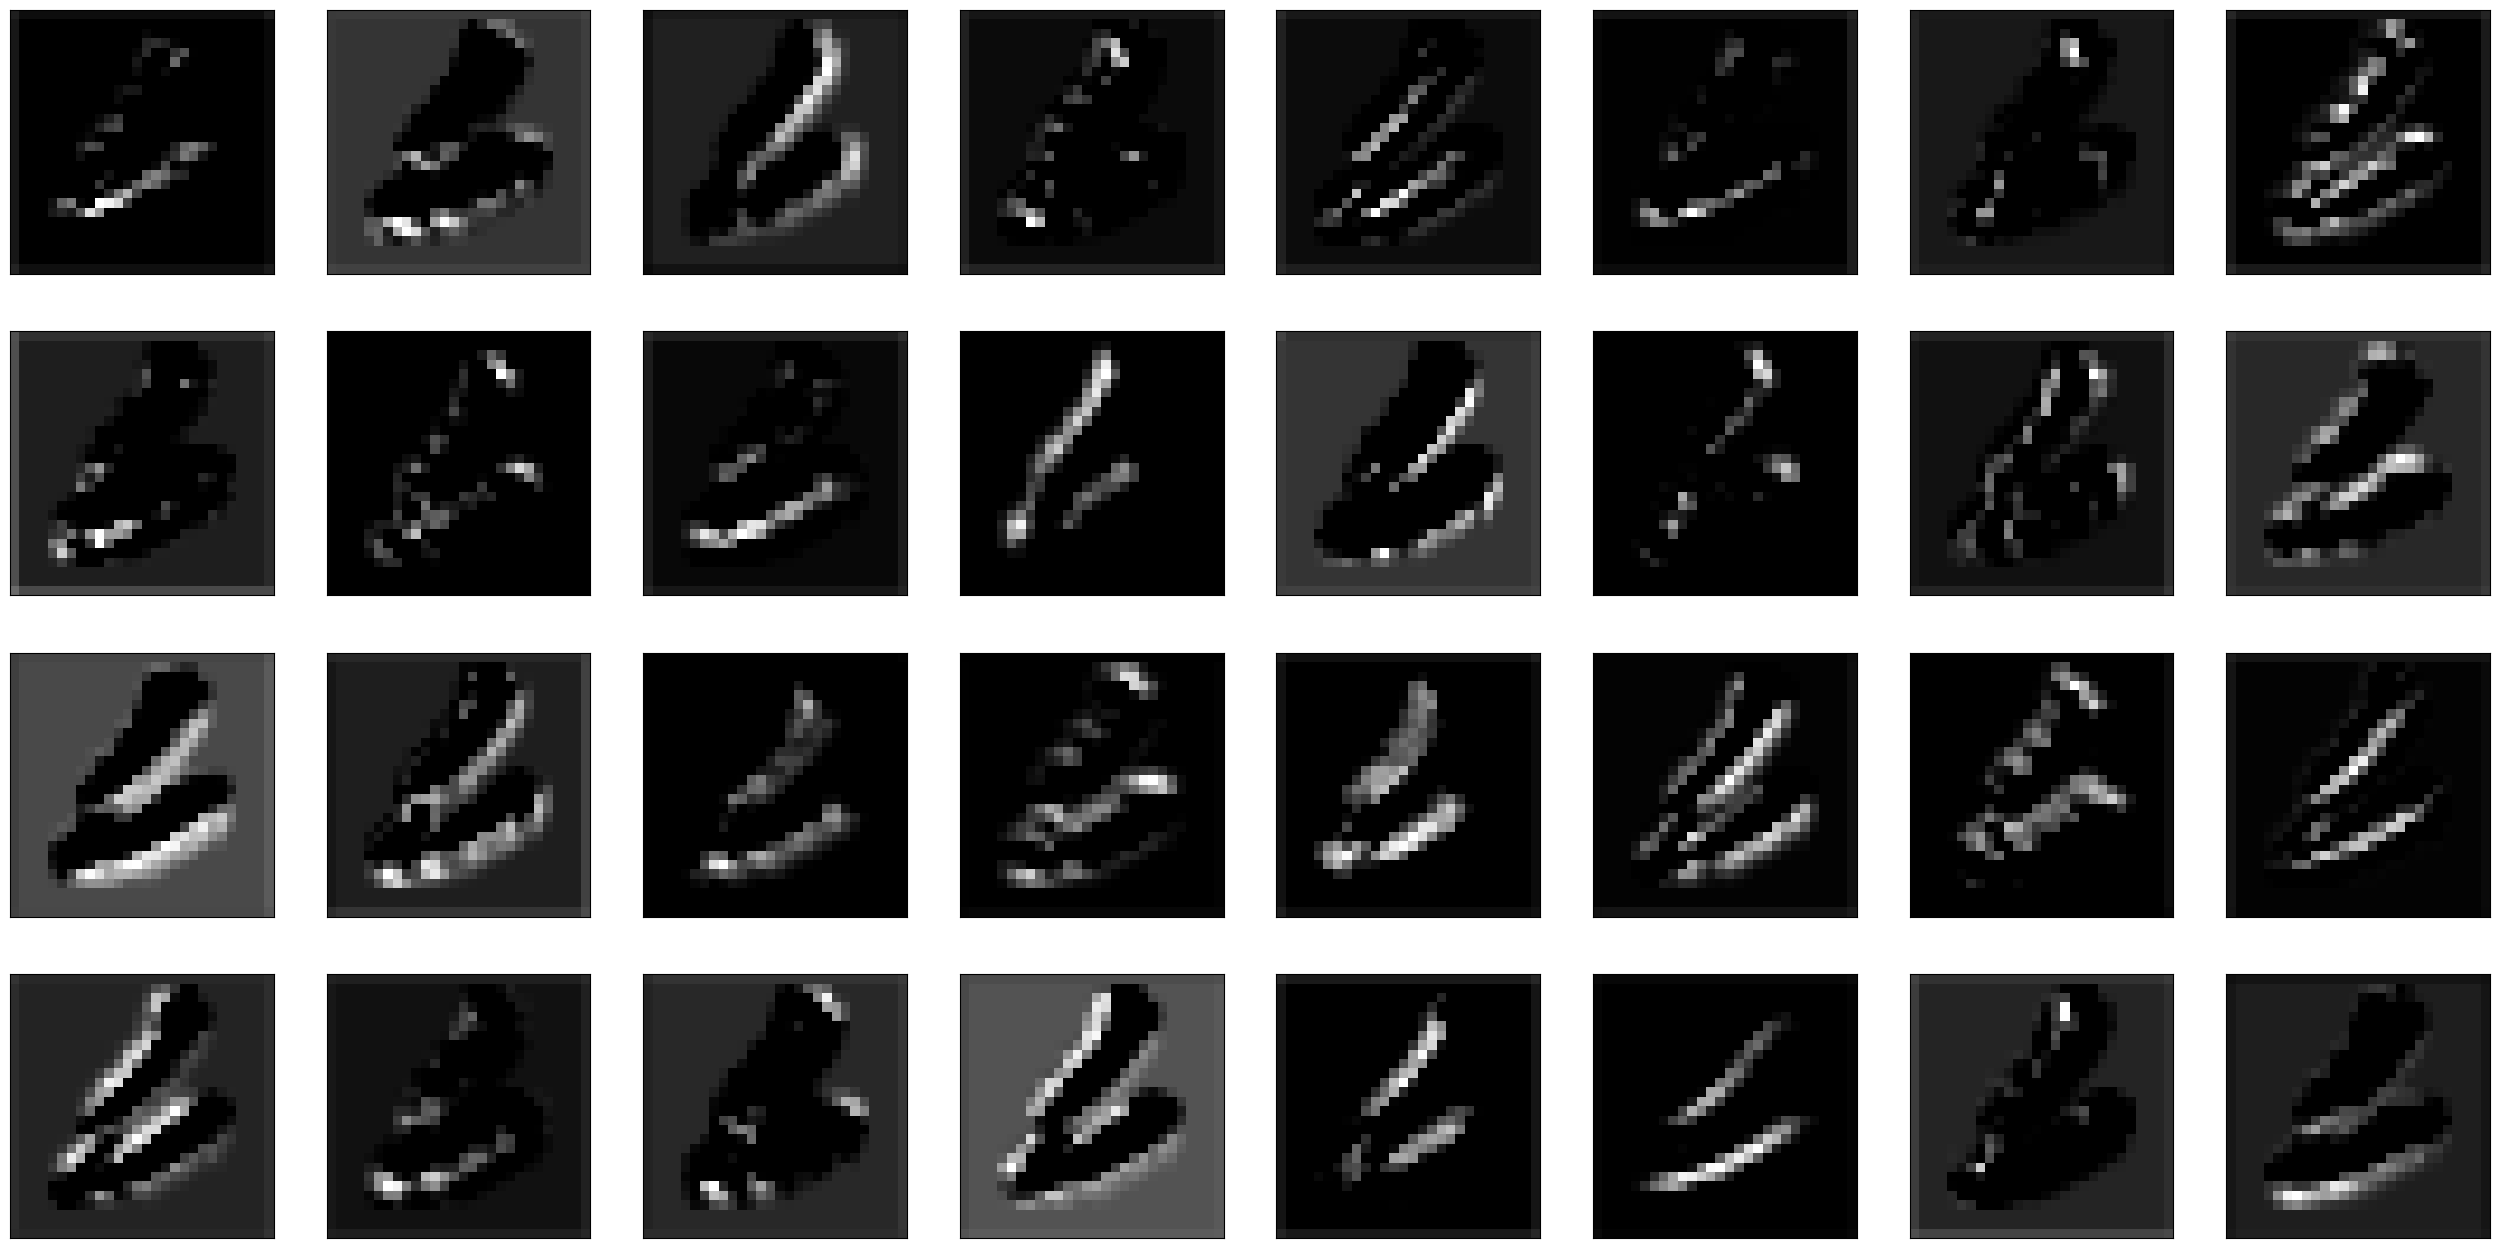

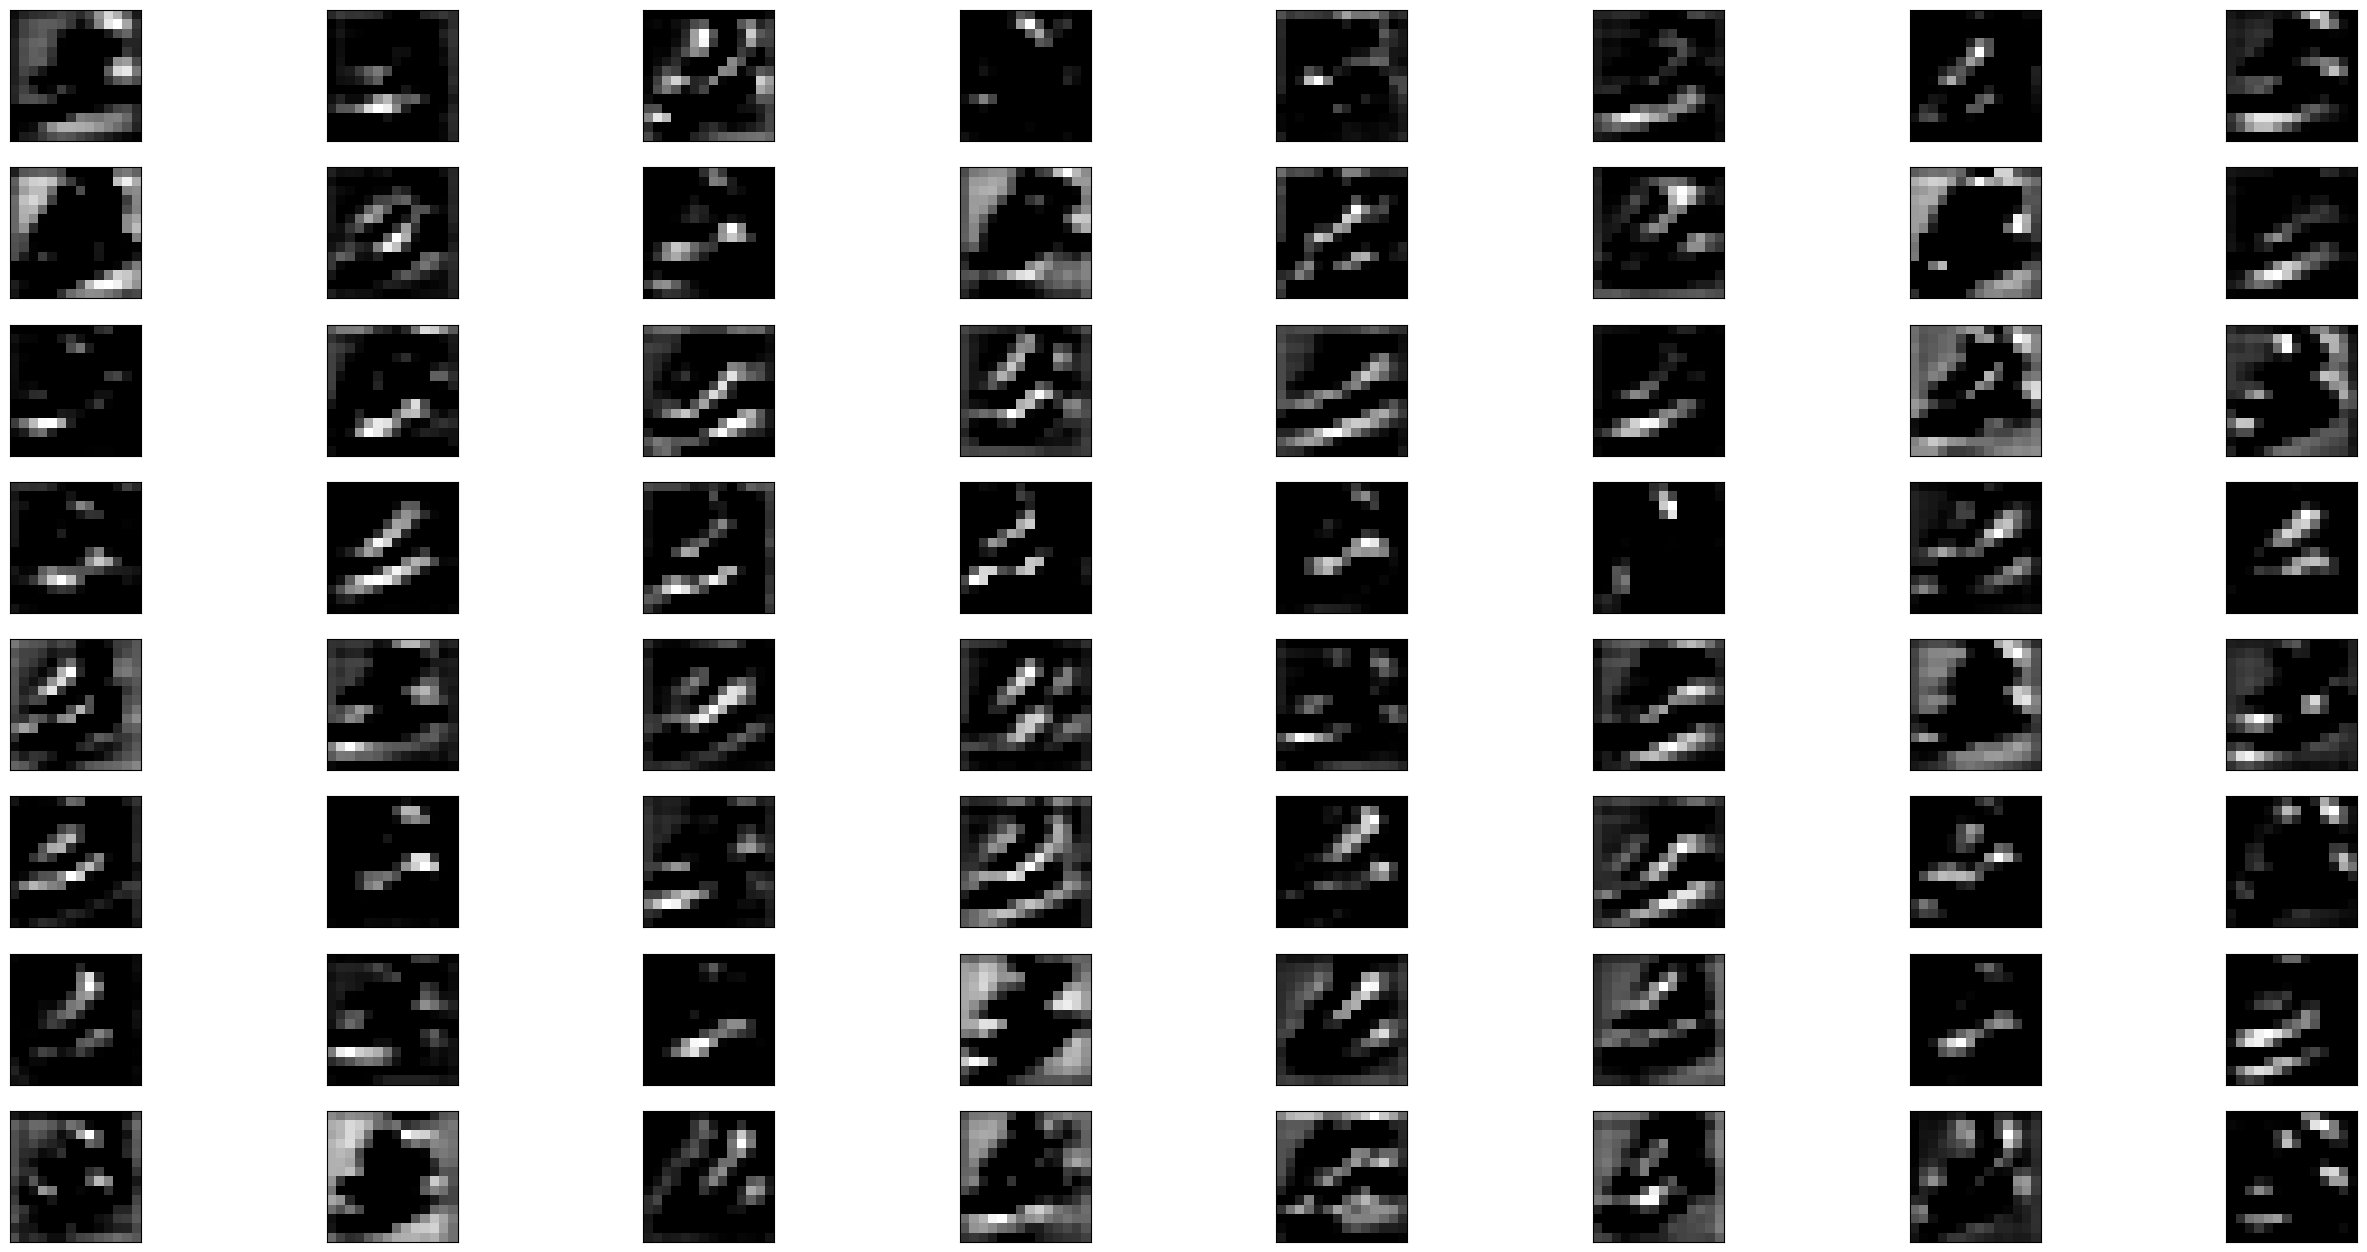

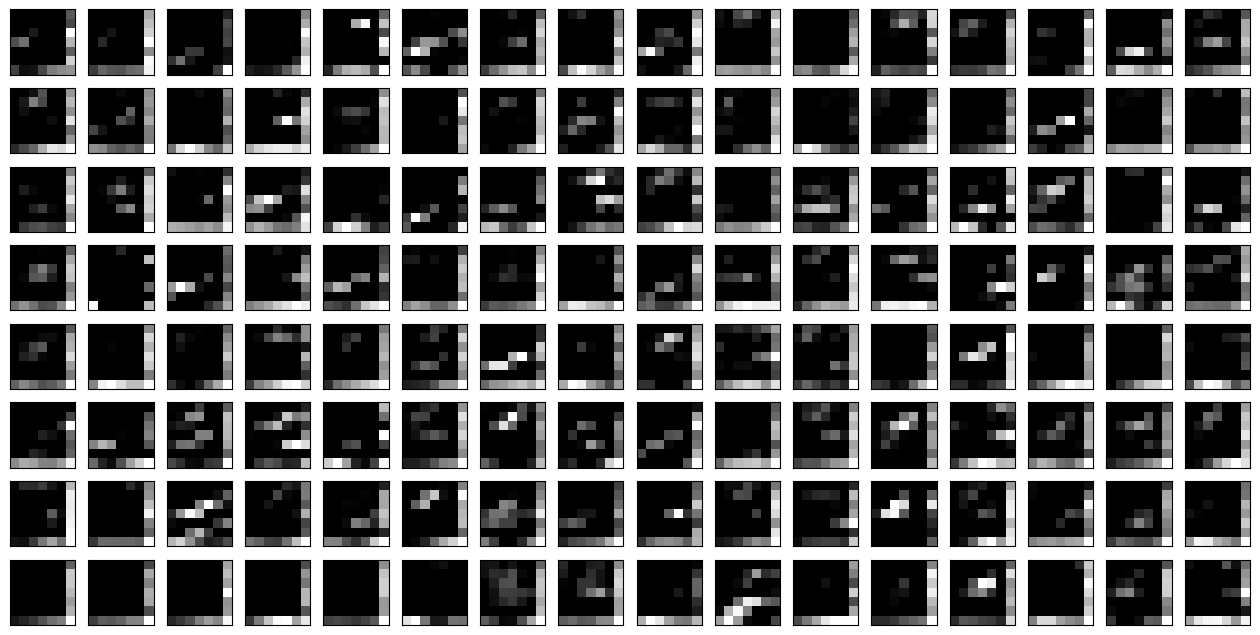

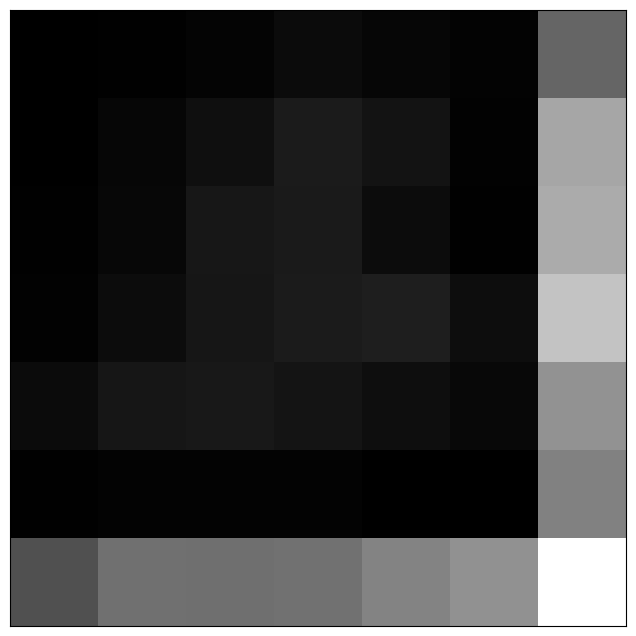

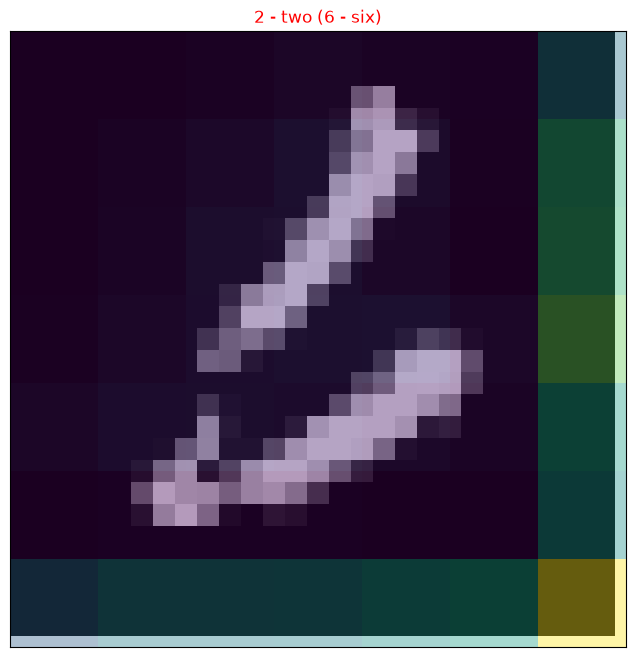

In [13]:
# 틀린거 뽑기
load_model.eval()
with torch.no_grad():
    wrong_image = None

    for x_batch, y_batch in test_DL:
        x_batch, y_batch = next(iter(test_DL))
        x_batch = x_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)
        y_hat = load_model(x_batch)
        pred = y_hat.argmax(dim=1)

        wrong_idx = torch.where(pred != y_batch)[0]

        if len(wrong_idx) > 0 :
            idx = wrong_idx[0].item()

            wrong_image = x_batch[idx:idx+1]

            pred_label = pred[idx].item()
            true_label = y_batch[idx].item()

    if wrong_image is not None :

        # CNN 할 때 사용
        # feature_map1 = load_model.conv1(wrong_image)
        # feature_map2 = load_model.conv2(load_model.Maxpool1(feature_map1))
        # feature_map3 = load_model.conv3(load_model.Maxpool2(feature_map2))

        # CNN_deep 할 때 사용
        feature_map1 = load_model.conv_block1(wrong_image)
        feature_map2 = load_model.conv_block2(load_model.Maxpool1(feature_map1))
        feature_map3 = load_model.conv_block3(load_model.Maxpool2(feature_map2))

wrong_image = wrong_image.cpu()
feature_map1 = feature_map1.cpu()
feature_map2 = feature_map2.cpu()
feature_map3 = feature_map3.cpu()

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(wrong_image[0,0], cmap='gray')

print(feature_map1.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map1.shape[1]):
    plt.subplot(4,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map1[0,idx], cmap='gray')

print(feature_map2.shape)
plt.figure(figsize=(32,16))
for idx in range(feature_map2.shape[1]):
    plt.subplot(8,8, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map2[0,idx], cmap='gray')

print(feature_map3.shape)
plt.figure(figsize=(16,8))
for idx in range(feature_map3.shape[1]):
    plt.subplot(8,16, idx+1, xticks=[], yticks=[])
    plt.imshow(feature_map3[0,idx], cmap='gray')

summed_map = feature_map3.sum(dim=1)
plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(summed_map[0], cmap='gray')

plt.figure(figsize=(8,8))
plt.xticks([])
plt.yticks([])
plt.imshow(wrong_image[0,0], cmap='gray')
plt.imshow(summed_map[0], extent=[0,28,28,0], alpha=0.4, cmap='viridis')
pred_item = test_DS.classes[pred_label]
true_item = test_DS.classes[true_label]
plt.title(f'{pred_item} ({true_item})', color='g' if pred_item == true_item else 'r')